<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/3_statistical_condensed/kinetic_theory/kintheory_ch3_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Kinetic Theory* — `kintheory_ch3_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Kinetic Theory Chapter 3 — Figures
**Kinetic Theory · Ch 3: Stochastic Processes**
Tong lectures — SeoulTech PSE Lab

Figures produced:
- `kt_fig10_brownian.png` — Brownian motion trajectories (multiple realisations)
- `kt_fig11_fokker_planck.png` — Spreading Gaussian P(x,t) and probability current
- `kt_fig12_escape.png` — Thermal escape over a potential barrier (Kramers problem)
- `kt_fig13_velocity_relax.png` — Velocity distribution relaxing to Maxwell-Boltzmann
- `kt_fig14_path_integral.png` — Chapman-Kolmogorov to path integral schematic

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Arc, Circle
from matplotlib.colors import LinearSegmentedColormap
import os

os.makedirs('figures', exist_ok=True)

BG      = '#0d1117'
SURFACE = '#161b22'
BORDER  = '#30363d'
TEXT    = '#e6edf3'
MUTED   = '#8b949e'
TEAL    = '#2dd4bf'
BLUE    = '#388bfd'
GREEN   = '#3fb950'
RED     = '#f85149'
PURPLE  = '#bc8cff'
ORANGE  = '#f0883e'

SAVE_KW = dict(dpi=150, bbox_inches='tight', facecolor=BG)

def setup_ax(ax):
    ax.set_facecolor(BG)
    for sp in ax.spines.values():
        sp.set_color(BORDER)
    ax.tick_params(colors=MUTED)
    ax.xaxis.label.set_color(TEXT)
    ax.yaxis.label.set_color(TEXT)
    ax.title.set_color(TEAL)

print('Setup complete.')

Setup complete.


## Fig 10 — Brownian Motion Trajectories

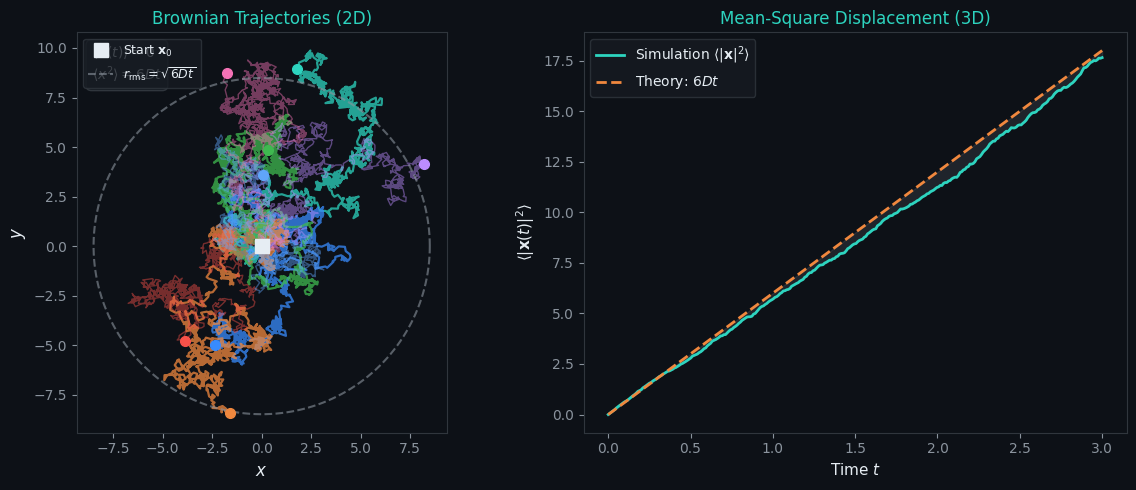

Saved kt_fig10_brownian.png


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.patch.set_facecolor(BG)

# ── Left: 2D Brownian trajectories ──
ax1 = axes[0]
setup_ax(ax1)

np.random.seed(42)
N_steps = 1200      # more steps for more dramatic spread
N_walkers = 8
dt = 0.01
D = 1.0
sigma = np.sqrt(2 * D * dt)

colors_w = [TEAL, BLUE, ORANGE, GREEN, RED, PURPLE, '#60a5fa', '#f472b6']

all_ends = []
for i in range(N_walkers):
    steps = np.random.normal(0, sigma, (N_steps, 2))
    traj = np.vstack([[0, 0], np.cumsum(steps, axis=0)])
    alpha = 0.75 if i < 4 else 0.45
    lw = 1.6 if i < 4 else 1.0
    ax1.plot(traj[:, 0], traj[:, 1], color=colors_w[i], lw=lw, alpha=alpha)
    ax1.plot(traj[-1, 0], traj[-1, 1], 'o', color=colors_w[i], ms=7, zorder=5)
    all_ends.append(traj[-1])

# Starting point
ax1.plot(0, 0, 's', color=TEXT, ms=10, zorder=6, label='Start $\\mathbf{x}_0$')

# RMS radius circle: sqrt(6Dt) at t = N_steps*dt
t_total = N_steps * dt
rms = np.sqrt(6 * D * t_total)
theta_c = np.linspace(0, 2*np.pi, 200)
ax1.plot(rms * np.cos(theta_c), rms * np.sin(theta_c),
         color=MUTED, lw=1.5, ls='--', alpha=0.6, label=r'$r_\mathrm{rms} = \sqrt{6Dt}$')

ax1.set_xlabel('$x$', fontsize=12)
ax1.set_ylabel('$y$', fontsize=12)
ax1.set_title('Brownian Trajectories (2D)', fontsize=12)
ax1.set_aspect('equal')
ax1.legend(fontsize=9, facecolor=SURFACE, edgecolor=BORDER, labelcolor=TEXT)

ax1.text(0.04, 0.97,
         r'$\langle \mathbf{x}(t) \rangle = 0$' + '\n' + r'$\langle x^2 \rangle = 6Dt$',
         transform=ax1.transAxes, fontsize=10, color=TEXT, va='top',
         bbox=dict(boxstyle='round,pad=0.4', facecolor=SURFACE, edgecolor=BORDER))

# ── Right: MSD vs time ──
ax2 = axes[1]
setup_ax(ax2)

np.random.seed(0)
N_ensemble = 500
N_t = 300
t_arr = np.linspace(0, 3, N_t)
dt2 = t_arr[1] - t_arr[0]

# Simulate 3D MSD via 3 independent 1D walks
msd = np.zeros(N_t)
for _ in range(N_ensemble):
    for dim in range(3):
        steps_1d = np.random.normal(0, np.sqrt(2 * D * dt2), N_t - 1)
        x_path = np.concatenate([[0], np.cumsum(steps_1d)])
        msd += x_path**2
msd /= N_ensemble

ax2.plot(t_arr, msd, color=TEAL, lw=2.0, label='Simulation $\\langle|\\mathbf{x}|^2\\rangle$')
ax2.plot(t_arr, 6 * D * t_arr, color=ORANGE, lw=2.0, ls='--', label=r'Theory: $6Dt$')
ax2.fill_between(t_arr, msd, 6*D*t_arr, alpha=0.15, color=MUTED)

ax2.set_xlabel('Time $t$', fontsize=11)
ax2.set_ylabel(r'$\langle |\mathbf{x}(t)|^2 \rangle$', fontsize=11)
ax2.set_title('Mean-Square Displacement (3D)', fontsize=12)
ax2.legend(fontsize=10, facecolor=SURFACE, edgecolor=BORDER, labelcolor=TEXT)

plt.tight_layout()
plt.savefig('figures/kt_fig10_brownian.png', **SAVE_KW)
plt.show()
print('Saved kt_fig10_brownian.png')

## Fig 11 — Fokker-Planck: Spreading Gaussian + Probability Current

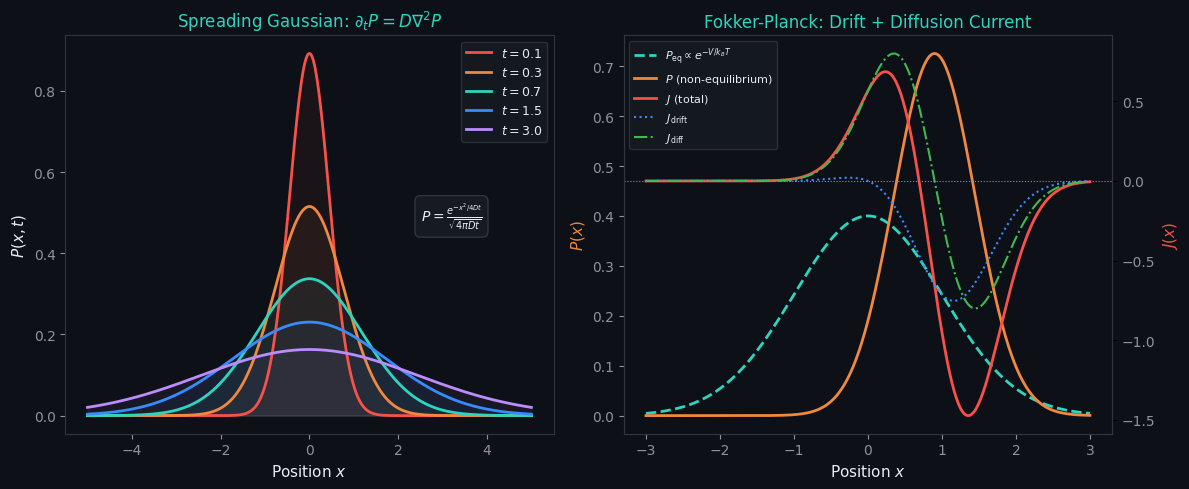

Saved kt_fig11_fokker_planck.png


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.patch.set_facecolor(BG)

# ── Left: P(x,t) spreading Gaussian ──
ax1 = axes[0]
setup_ax(ax1)

x = np.linspace(-5, 5, 500)
D = 1.0
times = [0.1, 0.3, 0.7, 1.5, 3.0]
colors_t = [RED, ORANGE, TEAL, BLUE, PURPLE]

for t_val, col in zip(times, colors_t):
    P = (1 / np.sqrt(4 * np.pi * D * t_val)) * np.exp(-x**2 / (4 * D * t_val))
    ax1.plot(x, P, color=col, lw=2.0, label=f'$t = {t_val}$')
    ax1.fill_between(x, P, alpha=0.06, color=col)

ax1.set_xlabel('Position $x$', fontsize=11)
ax1.set_ylabel('$P(x,t)$', fontsize=11)
ax1.set_title(r'Spreading Gaussian: $\partial_t P = D\nabla^2 P$', fontsize=12)
ax1.legend(fontsize=9, facecolor=SURFACE, edgecolor=BORDER, labelcolor=TEXT)

ax1.text(3.2, 0.48,
         r'$P = \frac{e^{-x^2/4Dt}}{\sqrt{4\pi Dt}}$',
         ha='center', fontsize=10, color=TEXT,
         bbox=dict(boxstyle='round,pad=0.4', facecolor=SURFACE, edgecolor=BORDER))

# ── Right: P(x) and J(x) on twin axes ──
ax2 = axes[1]
setup_ax(ax2)

x2 = np.linspace(-3, 3, 400)
gamma = 1.0
kBT = 1.0
D2 = kBT / gamma

# Harmonic potential V = 0.5 x^2
V = 0.5 * x2**2
dV_dx = x2   # dV/dx

# Non-equilibrium distribution: displaced Gaussian
x_shift = 0.9
P_neq = np.exp(-(x2 - x_shift)**2 / (2 * 0.55**2))
P_neq /= np.trapezoid(P_neq, x2)

# Equilibrium: P_eq propto exp(-V/kBT)
P_eq = np.exp(-V / kBT)
P_eq /= np.trapezoid(P_eq, x2)

# Probability current J = -P * dV/dx / gamma + D * dP/dx
dP_dx = np.gradient(P_neq, x2)
J = -P_neq * dV_dx / gamma + D2 * dP_dx

# Decompose into drift and diffusion contributions
J_drift = -P_neq * dV_dx / gamma
J_diff  =  D2 * dP_dx

# P on left axis
ax2.plot(x2, P_eq,  color=TEAL,   lw=2.0, ls='--', label=r'$P_{\rm eq} \propto e^{-V/k_BT}$')
ax2.plot(x2, P_neq, color=ORANGE, lw=2.0, label='$P$ (non-equilibrium)')
ax2.set_xlabel('Position $x$', fontsize=11)
ax2.set_ylabel('$P(x)$', fontsize=11, color=ORANGE)
ax2.tick_params(axis='y', labelcolor=MUTED)

# J on twin right axis
ax2r = ax2.twinx()
ax2r.set_facecolor(BG)
ax2r.plot(x2, J,       color=RED,    lw=2.0,       label=r'$J$ (total)')
ax2r.plot(x2, J_drift, color=BLUE,   lw=1.5, ls=':', label=r'$J_{\rm drift}$')
ax2r.plot(x2, J_diff,  color=GREEN,  lw=1.5, ls='-.', label=r'$J_{\rm diff}$')
ax2r.axhline(0, color=MUTED, lw=0.8, ls=':')
ax2r.set_ylabel('$J(x)$', fontsize=11, color=RED)
ax2r.tick_params(axis='y', labelcolor=MUTED)
for sp in ax2r.spines.values():
    sp.set_color(BORDER)

# Combined legend
lines1, labs1 = ax2.get_legend_handles_labels()
lines2, labs2 = ax2r.get_legend_handles_labels()
ax2r.legend(lines1 + lines2, labs1 + labs2,
            fontsize=8, facecolor=SURFACE, edgecolor=BORDER, labelcolor=TEXT,
            loc='upper left')

ax2.set_title('Fokker-Planck: Drift + Diffusion Current', fontsize=12)

plt.tight_layout()
plt.savefig('figures/kt_fig11_fokker_planck.png', **SAVE_KW)
plt.show()
print('Saved kt_fig11_fokker_planck.png')

## Fig 12 — Thermal Escape over a Barrier (Kramers Problem)

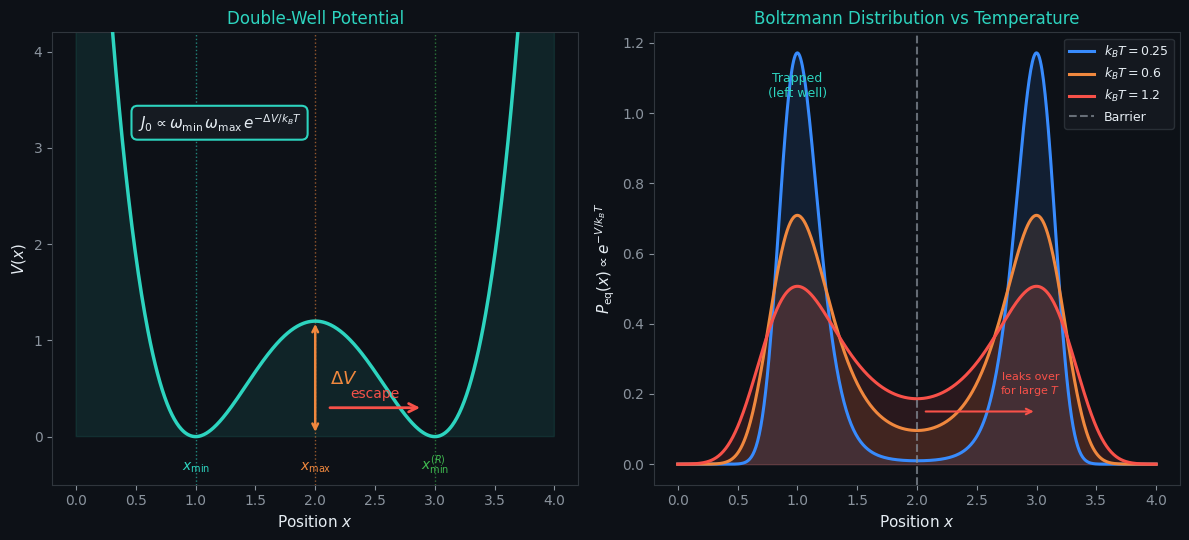

Saved kt_fig12_escape.png


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
fig.patch.set_facecolor(BG)

# ── Left: potential V(x) — proper double-well ──
ax1 = axes[0]
setup_ax(ax1)

x = np.linspace(0.0, 4.0, 600)
# Double-well: V = a*(x-1)^2*(x-3)^2, minimum at x=1 and x=3
a = 1.2
V_raw = a * (x - 1.0)**2 * (x - 3.0)**2
# Shift so left minimum = 0
V_left_min = np.min(V_raw[x < 2])
V = V_raw - V_left_min

x_min_L = 1.0        # left minimum
x_saddle = 2.0       # barrier top (saddle)
x_min_R = 3.0        # right minimum (exit)

V_at_minL   = np.interp(x_min_L, x, V)   # = 0
V_at_saddle = np.interp(x_saddle, x, V)  # barrier height
V_at_minR   = np.interp(x_min_R, x, V)   # right minimum

ax1.plot(x, V, color=TEAL, lw=2.5, zorder=3)
ax1.fill_between(x, V, alpha=0.10, color=TEAL)

# Barrier height arrow
ax1.annotate('', xy=(x_saddle, V_at_saddle), xytext=(x_saddle, V_at_minL + 0.02),
             arrowprops=dict(arrowstyle='<->', color=ORANGE, lw=1.8))
ax1.text(x_saddle + 0.12, (V_at_saddle + V_at_minL) / 2,
         r'$\Delta V$', fontsize=13, color=ORANGE, va='center')

# Vertical markers
for xi, lbl, col in [(x_min_L, '$x_{\\min}$', TEAL),
                     (x_saddle, '$x_{\\max}$', ORANGE),
                     (x_min_R, '$x_{\\min}^{(R)}$', GREEN)]:
    ax1.axvline(xi, color=col, lw=1.0, ls=':', alpha=0.6)
    ax1.text(xi, -0.35, lbl, ha='center', fontsize=10, color=col)

# Escape arrow
ax1.annotate('', xy=(x_min_R - 0.1, 0.3), xytext=(x_saddle + 0.1, 0.3),
             arrowprops=dict(arrowstyle='->', color=RED, lw=2.0, mutation_scale=15))
ax1.text((x_saddle + x_min_R)/2, 0.4, 'escape', ha='center', fontsize=10, color=RED)

# Kramers rate box
ax1.text(1.2, 3.2,
         r'$J_0 \propto \omega_{\min}\,\omega_{\max}\,e^{-\Delta V/k_BT}$',
         ha='center', fontsize=11, color=TEXT,
         bbox=dict(boxstyle='round,pad=0.4', facecolor=SURFACE, edgecolor=TEAL, lw=1.5))

ax1.set_xlabel('Position $x$', fontsize=11)
ax1.set_ylabel('$V(x)$', fontsize=11)
ax1.set_title('Double-Well Potential', fontsize=12)
ax1.set_ylim(-0.5, 4.2)

# ── Right: Boltzmann distributions for three temperatures ──
ax2 = axes[1]
setup_ax(ax2)

kBT_vals = [0.25, 0.6, 1.2]
colors_kT = [BLUE, ORANGE, RED]
labels_kT = [f'$k_BT = {v}$' for v in kBT_vals]

for kBT, col, lbl in zip(kBT_vals, colors_kT, labels_kT):
    P = np.exp(-V / kBT)
    P /= np.trapezoid(P, x)   # normalise
    ax2.plot(x, P, color=col, lw=2.2, label=lbl)
    ax2.fill_between(x, P, alpha=0.12, color=col)

# Barrier position
ax2.axvline(x_saddle, color=MUTED, lw=1.5, ls='--', alpha=0.7, label='Barrier')

# Annotations
ax2.text(1.0, ax2.get_ylim()[1]*0.85 if ax2.get_ylim()[1] > 0 else 1.0,
         'Trapped\n(left well)', ha='center', fontsize=9, color=TEAL)
ax2.annotate('', xy=(x_min_R, 0.15), xytext=(x_saddle + 0.05, 0.15),
             arrowprops=dict(arrowstyle='->', color=RED, lw=1.5))
ax2.text(2.95, 0.20, 'leaks over\nfor large $T$', ha='center', fontsize=8, color=RED)

ax2.set_xlabel('Position $x$', fontsize=11)
ax2.set_ylabel('$P_\\mathrm{eq}(x) \\propto e^{-V/k_BT}$', fontsize=11)
ax2.set_title('Boltzmann Distribution vs Temperature', fontsize=12)
ax2.legend(fontsize=9, facecolor=SURFACE, edgecolor=BORDER, labelcolor=TEXT)

plt.tight_layout()
plt.savefig('figures/kt_fig12_escape.png', **SAVE_KW)
plt.show()
print('Saved kt_fig12_escape.png')

## Fig 13 — Velocity Distribution Relaxing to Maxwell-Boltzmann

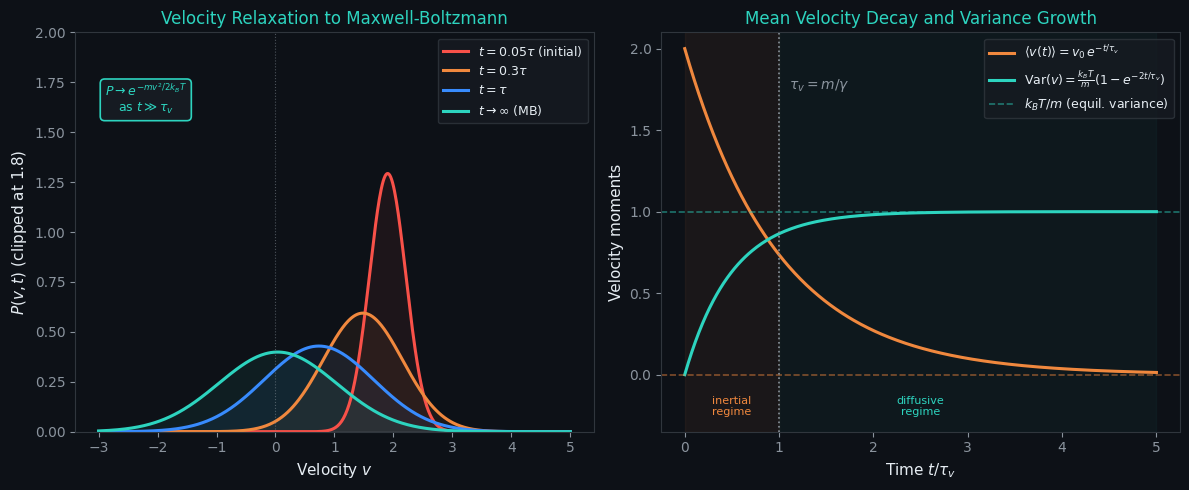

Saved kt_fig13_velocity_relax.png


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.patch.set_facecolor(BG)

m = 1.0
gamma = 1.0
kBT = 1.0
v0 = 2.0
tau = m / gamma

v = np.linspace(-3, 5, 500)
times = [0.05, 0.3, 1.0, 4.0]
colors_t = [RED, ORANGE, BLUE, TEAL]
labels_t = ['$t=0.05\\tau$ (initial)', f'$t=0.3\\tau$', f'$t=\\tau$',
            f'$t\\to\\infty$ (MB)']

# ── Left: P(v,t) ──
ax1 = axes[0]
setup_ax(ax1)

for t_val, col, lbl in zip(times, colors_t, labels_t):
    v_mean = v0 * np.exp(-t_val / tau)
    sigma2 = (kBT / m) * (1 - np.exp(-2 * t_val / tau))
    sigma2 = max(sigma2, 1e-4)
    P = np.exp(-(v - v_mean)**2 / (2 * sigma2)) / np.sqrt(2 * np.pi * sigma2)
    # Clip peak so all curves are on the same visual scale
    P_plot = np.minimum(P, 1.8)
    ax1.plot(v, P_plot, color=col, lw=2.2, label=lbl)
    ax1.fill_between(v, P_plot, alpha=0.07, color=col)

ax1.axvline(0, color=MUTED, lw=0.8, ls=':', alpha=0.5)
ax1.set_xlabel('Velocity $v$', fontsize=11)
ax1.set_ylabel('$P(v,t)$ (clipped at 1.8)', fontsize=11)
ax1.set_title('Velocity Relaxation to Maxwell-Boltzmann', fontsize=12)
ax1.legend(fontsize=9, facecolor=SURFACE, edgecolor=BORDER, labelcolor=TEXT)
ax1.set_ylim(0, 2.0)

ax1.text(-2.2, 1.6,
         r'$P \to e^{-mv^2/2k_BT}$' + '\n' + r'as $t \gg \tau_v$',
         ha='center', fontsize=9, color=TEAL,
         bbox=dict(boxstyle='round,pad=0.35', facecolor=SURFACE, edgecolor=TEAL, lw=1.2))

# ── Right: mean velocity and variance vs time ──
ax2 = axes[1]
setup_ax(ax2)

t_plot = np.linspace(0, 5, 400)
v_mean_t = v0 * np.exp(-t_plot / tau)
var_t    = (kBT / m) * (1 - np.exp(-2 * t_plot / tau))

ax2.plot(t_plot, v_mean_t, color=ORANGE, lw=2.2,
         label=r'$\langle v(t)\rangle = v_0\,e^{-t/\tau_v}$')
ax2.plot(t_plot, var_t,    color=TEAL,   lw=2.2,
         label=r'$\mathrm{Var}(v) = \frac{k_BT}{m}(1-e^{-2t/\tau_v})$')

# Equilibrium dashed lines
ax2.axhline(kBT / m, color=TEAL,   lw=1.2, ls='--', alpha=0.5,
            label=r'$k_BT/m$ (equil. variance)')
ax2.axhline(0,       color=ORANGE, lw=1.2, ls='--', alpha=0.5)

# Relaxation time marker
ax2.axvline(tau, color=MUTED, lw=1.2, ls=':')
ax2.text(tau + 0.1, 1.75, r'$\tau_v = m/\gamma$', fontsize=10, color=MUTED)

# Shading: region t < tau
ax2.axvspan(0, tau, alpha=0.06, color=ORANGE)
ax2.text(tau/2, -0.25, 'inertial\nregime', ha='center', fontsize=8, color=ORANGE)
ax2.axvspan(tau, 5, alpha=0.04, color=TEAL)
ax2.text(tau*2.5, -0.25, 'diffusive\nregime', ha='center', fontsize=8, color=TEAL)

ax2.set_xlabel('Time $t/\\tau_v$', fontsize=11)
ax2.set_ylabel('Velocity moments', fontsize=11)
ax2.set_title('Mean Velocity Decay and Variance Growth', fontsize=12)
ax2.legend(fontsize=9, facecolor=SURFACE, edgecolor=BORDER, labelcolor=TEXT)
ax2.set_ylim(-0.35, 2.1)

plt.tight_layout()
plt.savefig('figures/kt_fig13_velocity_relax.png', **SAVE_KW)
plt.show()
print('Saved kt_fig13_velocity_relax.png')

## Fig 14 — Chapman-Kolmogorov to Path Integral Schematic

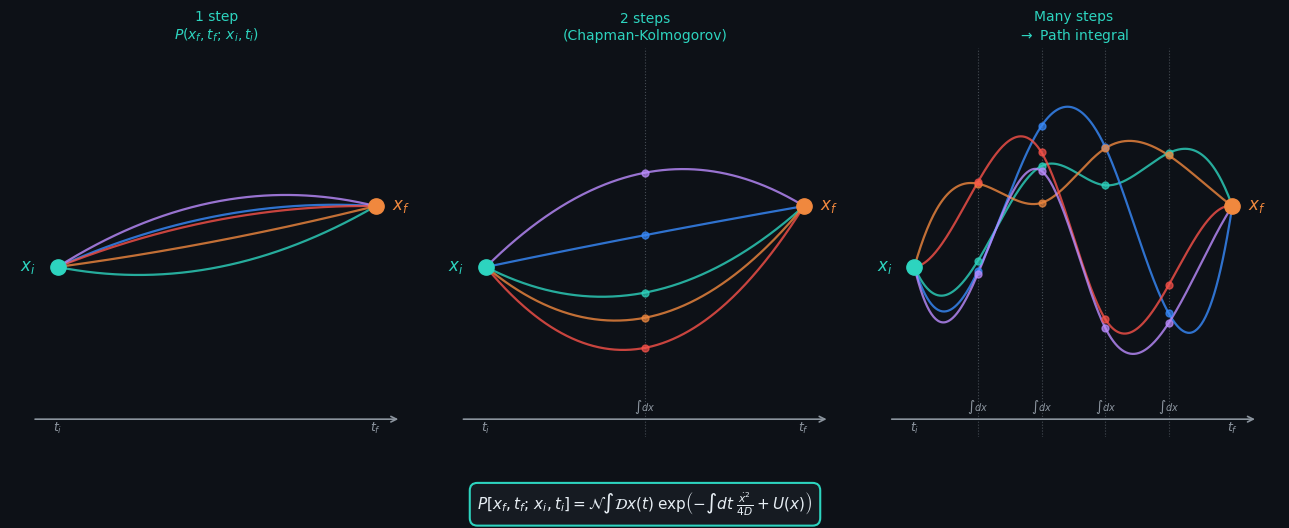

Saved kt_fig14_path_integral.png


In [6]:
from scipy.interpolate import CubicSpline

fig, axes = plt.subplots(1, 3, figsize=(13, 5.2))
fig.patch.set_facecolor(BG)

def draw_panel(ax, n_intermediate, title, seed_offset=0):
    ax.set_facecolor(BG)
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlim(-0.15, 1.15)
    ax.set_ylim(-1.6, 1.6)

    # Fixed endpoints
    t0, tf = 0.0, 1.0
    y0, yf = -0.2, 0.3
    colors_paths = [TEAL, BLUE, ORANGE, RED, PURPLE]

    np.random.seed(7 + seed_offset)
    for i, col in enumerate(colors_paths):
        # Build smooth random path via cubic spline
        if n_intermediate == 0:
            # Direct path — slightly curved
            t_knots = np.array([t0, 0.5, tf])
            y_knots = np.array([y0, (y0 + yf)/2 + np.random.uniform(-0.3, 0.3), yf])
        else:
            t_knots = np.linspace(t0, tf, n_intermediate + 2)
            y_mid   = np.random.uniform(-1.0, 1.0, n_intermediate)
            y_knots = np.concatenate([[y0], y_mid, [yf]])

        cs = CubicSpline(t_knots, y_knots, bc_type='not-a-knot')
        t_fine = np.linspace(t0, tf, 300)
        y_fine = cs(t_fine)

        ax.plot(t_fine, y_fine, color=col, lw=1.6, alpha=0.80)

        # Mark intermediate knot points
        if n_intermediate > 0:
            for j in range(1, len(t_knots) - 1):
                ax.plot(t_knots[j], y_knots[j], 'o',
                        color=col, ms=5, alpha=0.7, zorder=5)

    # Vertical dashed lines at intermediate times
    if n_intermediate > 0:
        for tp in np.linspace(t0, tf, n_intermediate + 2)[1:-1]:
            ax.axvline(tp, color=MUTED, lw=0.8, ls=':', alpha=0.45)
            ax.text(tp, -1.38, r'$\int dx$', ha='center', fontsize=7, color=MUTED)

    # Endpoints
    ax.plot(t0, y0, 'o', color=TEAL,   ms=11, zorder=7)
    ax.plot(tf, yf, 'o', color=ORANGE, ms=11, zorder=7)
    ax.text(t0 - 0.07, y0, '$x_i$', ha='right', fontsize=12, color=TEAL, va='center')
    ax.text(tf + 0.05, yf, '$x_f$', ha='left',  fontsize=12, color=ORANGE, va='center')

    # Time axis
    ax.annotate('', xy=(tf + 0.08, -1.45), xytext=(t0 - 0.08, -1.45),
                arrowprops=dict(arrowstyle='->', color=MUTED, lw=1.2))
    ax.text(0.0, -1.55, '$t_i$', ha='center', fontsize=9, color=MUTED)
    ax.text(1.0, -1.55, '$t_f$', ha='center', fontsize=9, color=MUTED)

    ax.set_title(title, color=TEAL, fontsize=10, pad=6)

draw_panel(axes[0], 0, '1 step\n$P(x_f,t_f;\\,x_i,t_i)$', seed_offset=0)
draw_panel(axes[1], 1, '2 steps\n(Chapman-Kolmogorov)', seed_offset=10)
draw_panel(axes[2], 4, 'Many steps\n$\\rightarrow$ Path integral', seed_offset=20)

# Global formula
fig.text(0.5, 0.01,
         r'$P[x_f,t_f;\,x_i,t_i] = \mathcal{N}\int\mathcal{D}x(t)\;\exp\!\left(-\int dt\;\frac{\dot{x}^2}{4D} + U(x)\right)$',
         ha='center', fontsize=11, color=TEXT,
         bbox=dict(boxstyle='round,pad=0.5', facecolor=SURFACE, edgecolor=TEAL, lw=1.5))

plt.tight_layout(rect=[0, 0.12, 1, 1])
plt.savefig('figures/kt_fig14_path_integral.png', **SAVE_KW)
plt.show()
print('Saved kt_fig14_path_integral.png')

## Download all figures as zip

In [7]:
import zipfile, os
zip_path = 'kt_ch3_figures.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    for fname in sorted(os.listdir('figures')):
        if fname.startswith('kt_fig1') and fname.endswith('.png'):
            fpath = os.path.join('figures', fname)
            zf.write(fpath, fname)
            print(f'  Added: {fname}')
print(f'\nZip: {zip_path}  ({os.path.getsize(zip_path)/1024:.1f} KB)')
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print('Not in Colab — file saved locally.')

  Added: kt_fig10_brownian.png
  Added: kt_fig11_fokker_planck.png
  Added: kt_fig12_escape.png
  Added: kt_fig13_velocity_relax.png
  Added: kt_fig14_path_integral.png

Zip: kt_ch3_figures.zip  (851.5 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>